# 🧰 Fourier + EDO — SEGUNDO PARCIAL — MODO EXAMEN PANELES ANTITONTO

Hecho con el mismo estilo de la herramienta del **Primer Parcial**:

## Cómo usarlo
1. Ejecuta **UNA VEZ** la celda azul **CARGAR HERRAMIENTA**.
2. Busca el panel del tipo de ejercicio.
3. Cambia únicamente lo que está bajo **✏️ EDITA SOLO AQUÍ**.
4. Ejecuta **ESA MISMA CELDA**.
5. La respuesta sale justo debajo.

**NO necesitas internet.**  
**NO necesitas escribir `sp.` en los datos de los paneles.**

---

## Convención principal para Transformada de Fourier

La clave de segundo parcial usa frecuencia angular:

\[
F(\omega)=\int_{-\infty}^{\infty}f(t)e^{-j\omega t}\,dt
\]

\[
f(t)=\frac{1}{2\pi}\int_{-\infty}^{\infty}F(\omega)e^{j\omega t}\,d\omega.
\]

Para Serie Compleja:

\[
c_n=\frac1T\int_T f(t)e^{-jn\omega_0t}\,dt,
\qquad
\omega_0=\frac{2\pi}{T}
\]

\[
f(t)=\sum_{n=-\infty}^{\infty}c_ne^{jn\omega_0t}.
\]

> ⚠️ No mezcles la convención en Hz \(e^{-j2\pi ft}\) con la convención en \(\omega\) \(e^{-j\omega t}\).

# 🔵 CARGAR HERRAMIENTA

Ejecuta la siguiente celda **una sola vez** al abrir el notebook.  
**No la edites.**

In [1]:
# ============================================================
# ⚙️ INTERNA — NO EDITAR
# SEGUNDO PARCIAL: FOURIER + EDO
# ============================================================

import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
import re

from IPython.display import display, Math, Markdown
from sympy.parsing.sympy_parser import (
    parse_expr,
    standard_transformations,
    implicit_multiplication_application,
    convert_xor,
)

sp.init_printing()

# ----------------------------
# VARIABLES
# ----------------------------
t = sp.symbols('t', real=True)
w = sp.symbols('w', real=True)
x = sp.symbols('x', real=True)
n = sp.symbols('n', integer=True)
nz = sp.symbols('n', integer=True, nonzero=True)
s = sp.symbols('s')
r = sp.symbols('r')
w0 = sp.symbols('w0', positive=True, real=True)
a = sp.symbols('a', positive=True, real=True)
A = sp.symbols('A', real=True)

pi = sp.pi
I = sp.I
j = sp.I
E = sp.E

sin = sp.sin
sen = sp.sin
cos = sp.cos
tan = sp.tan
exp = sp.exp
sqrt = sp.sqrt
Abs = sp.Abs
atan = sp.atan
Heaviside = sp.Heaviside
DiracDelta = sp.DiracDelta
oo = sp.oo

_TRANSFORMACIONES = standard_transformations + (
    implicit_multiplication_application,
    convert_xor,
)

_DICC = {
    't': t, 'w': w, 'omega': w, 'ω': w,
    'x': x, 'n': n,
    'pi': pi, 'I': I, 'j': I, 'E': E, 'e': E,
    'sin': sin, 'sen': sin, 'cos': cos, 'tan': tan,
    'exp': exp, 'sqrt': sqrt, 'Abs': Abs, 'abs': Abs,
    'atan': atan, 'Heaviside': Heaviside, 'u': Heaviside,
    'DiracDelta': DiracDelta, 'delta': DiracDelta,
    'oo': oo, 'inf': oo,'w0': w0, 'a': a,'A': A,
}

def F(valor, extra=None):
    """Parser amigable: acepta π, ^, e^, sen, 2t, 2πt, etc."""
    if isinstance(valor, sp.Basic):
        return valor
    if isinstance(valor, (int, float, np.integer, np.floating)):
        return sp.nsimplify(valor)
    texto = str(valor).strip()
    texto = texto.replace('π', 'pi')
    texto = texto.replace('ω', 'w')
    texto = texto.replace('·', '*').replace('×', '*')
    texto = texto.replace('−', '-').replace('–', '-')
    texto = texto.replace('sen', 'sin')
    texto = re.sub(r'(?<=\d),(?=\d)', '.', texto)
    local = dict(_DICC)
    if extra:
        local.update(extra)
    try:
        expr = parse_expr(
            texto,
            local_dict=local,
            transformations=_TRANSFORMACIONES,
            evaluate=True,
        )
        return sp.nsimplify(expr)
    except Exception as e:
        raise ValueError(f"No pude interpretar: {valor}\nDetalle: {e}")

def _lim(v):
    if isinstance(v, str):
        vv = v.strip().lower()
        if vv in ('inf','+inf','oo','+oo','infinito','+infinito'):
            return sp.oo
        if vv in ('-inf','-oo','-infinito'):
            return -sp.oo
    return F(v)

def _latex_eq(izq, expr):
    display(Math(izq + " = " + sp.latex(sp.simplify(expr))))

def _titulo(txt):
    display(Markdown("### " + txt))

def _nota(txt):
    display(Markdown("> " + txt))

def _subs_n(expr, k):
    expr = sp.sympify(expr)
    # Puede contener n o nz, ambos se llaman visualmente n.
    return sp.simplify(expr.subs({n:k, nz:k}))

def _tramos_integral(tramos, kernel, var=t):
    total = 0
    for expr, a, b in tramos:
        total += sp.integrate(F(expr)*kernel, (var, F(a), F(b)))
    return sp.simplify(total)

# ============================================================
# AYUDA / SELECTOR
# ============================================================

def ayuda_segundo():
    display(Markdown(r"""
## 🧭 ¿QUÉ PANEL USO?

| Si el problema dice... | Usa |
|---|---|
| **Serie compleja de Fourier** de una fórmula | **Panel 1** |
| Serie compleja **por tramos** | **Panel 2** |
| TF **por definición / integral** | **Panel 3** |
| TF por integral de una señal **por tramos** | **Panel 4** |
| **Transformada inversa** | **Panel 5** |
| Multiplicar por \(e^{j\omega_0t}\), coseno o seno | **Panel 6** |
| Señal movida \(f(t-t_0)\), \(f(t+5)\) | **Panel 7** |
| Señal **ampliada / alargada / movida** | **Panel 8** |
| Te dan \(x(at+b)\) directamente | **Panel 9** |
| **Dualidad** | **Panel 10** |
| Constante + senos/cosenos → **deltas** | **Panel 11** |
| Dibujar \(|F(\omega)|\) y fase | **Panel 12** |
| EDO con entrada periódica **por tramos** | **Panel 13** |
| EDO cuando ya conoces \(c_n\) | **Panel 14** |
| Hay **resonancia** | **Panel 15** |
| Circuito **RC pasa bajo** | **Panel 16** |
| EDO térmica \(y'+ay=\) serie seno/coseno | **Panel 17** |
| RLC \(q''+2\alpha q'+\omega^2q=\omega^2E\) | **Panel 18** |
| Viga / cuarta derivada con serie seno | **Panel 19** |
| Ver formulario rápido | **Panel F0** |
"""))

# ============================================================
# SERIE COMPLEJA
# ============================================================

def resolver_scf(funcion, desde, hasta, periodo=None, N=5):
    f = F(funcion)
    a, b = F(desde), F(hasta)
    T = F(periodo) if periodo is not None else sp.simplify(b-a)
    w0 = sp.simplify(2*pi/T)

    c0 = sp.simplify(sp.integrate(f, (t,a,b))/T)
    cn = sp.simplify(sp.integrate(
        f*sp.exp(-I*nz*w0*t), (t,a,b)
    )/T)

    _titulo("Serie compleja de Fourier")
    _latex_eq(r"T", T)
    _latex_eq(r"\omega_0", w0)
    _latex_eq(r"c_0", c0)
    _latex_eq(r"c_n\;(n\neq0)", cn)

    display(Math(
        r"f(t)=" + sp.latex(c0) +
        r"+\sum_{\substack{n=-\infty\\n\neq0}}^{\infty}"
        r"\left(" + sp.latex(cn) + r"\right)e^{jn\omega_0t}"
    ))

    print("\nCoeficientes de comprobación:")
    for k in range(-N, N+1):
        if k == 0:
            ck = c0
        else:
            ck = _subs_n(cn, k)
        print(f"n={k:>3}: c_n = {sp.simplify(ck)}")

    return {'f':f,'T':T,'w0':w0,'c0':c0,'cn':cn}

def resolver_scf_tramos(tramos, periodo, N=5):
    T = F(periodo)
    w0 = sp.simplify(2*pi/T)

    c0 = sp.simplify(
        sum(sp.integrate(F(expr),(t,F(a),F(b))) for expr,a,b in tramos)/T
    )
    cn = sp.simplify(
        sum(sp.integrate(
            F(expr)*sp.exp(-I*nz*w0*t),
            (t,F(a),F(b))
        ) for expr,a,b in tramos)/T
    )

    _titulo("Serie compleja por tramos")
    _latex_eq(r"T", T)
    _latex_eq(r"\omega_0", w0)
    _latex_eq(r"c_0", c0)
    _latex_eq(r"c_n\;(n\neq0)", cn)

    display(Math(
        r"f(t)=" + sp.latex(c0) +
        r"+\sum_{\substack{n=-\infty\\n\neq0}}^{\infty}"
        r"\left(" + sp.latex(cn) + r"\right)e^{jn\omega_0t}"
    ))

    print("\nCoeficientes de comprobación:")
    for k in range(-N, N+1):
        ck = c0 if k == 0 else _subs_n(cn,k)
        print(f"n={k:>3}: c_n = {sp.simplify(ck)}")

    return {'T':T,'w0':w0,'c0':c0,'cn':cn}

# ============================================================
# TRANSFORMADA DE FOURIER DIRECTA / INVERSA
# ============================================================

def resolver_tf_integral(funcion, desde, hasta):
    fexpr = F(funcion)
    a,b = _lim(desde), _lim(hasta)

    integrando = sp.simplify(fexpr*sp.exp(-I*w*t))
    resultado = sp.simplify(sp.integrate(integrando,(t,a,b)))

    _titulo("Transformada de Fourier por definición")
    _latex_eq(r"f(t)", fexpr)
    display(Math(
        r"F(\omega)=\int_{" + sp.latex(a) + r"}^{" + sp.latex(b) + r"}"
        + sp.latex(fexpr) + r"e^{-j\omega t}\,dt"
    ))
    _latex_eq(r"F(\omega)", resultado)
    return resultado

def resolver_tf_tramos(tramos):
    total = 0
    _titulo("Transformada de Fourier por tramos")
    for i,(expr,a,b) in enumerate(tramos,1):
        ex=F(expr); aa=_lim(a); bb=_lim(b)
        parte=sp.integrate(ex*sp.exp(-I*w*t),(t,aa,bb))
        total += parte
        display(Math(
            rf"F_{i}(\omega)=\int_{{{sp.latex(aa)}}}^{{{sp.latex(bb)}}}"
            + sp.latex(ex) + r"e^{-j\omega t}\,dt"
        ))
    total=sp.simplify(total)
    _latex_eq(r"F(\omega)", total)
    return total

def resolver_tfi_integral(Fomega, desde="-oo", hasta="oo"):
    X = F(Fomega)
    a,b=_lim(desde),_lim(hasta)
    integrando=sp.simplify(X*sp.exp(I*w*t)/(2*pi))
    resultado=sp.integrate(integrando,(w,a,b))
    _titulo("Transformada inversa de Fourier")
    display(Math(
        r"f(t)=\frac{1}{2\pi}\int_{" + sp.latex(a) + r"}^{" + sp.latex(b) + r"}"
        + sp.latex(X) + r"e^{j\omega t}\,d\omega"
    ))
    _latex_eq(r"f(t)", resultado)
    return resultado

# ============================================================
# PROPIEDADES / CORRIMIENTOS
# ============================================================

def resolver_corrimiento_frecuencia(Fbase, tipo="cos", w0=1, amplitud=1):
    X=F(Fbase)
    wm=F(w0)
    A=F(amplitud)
    tipo=str(tipo).lower().strip()

    _titulo("Traslación en frecuencia")
    _latex_eq(r"X(\omega)", X)

    if tipo in ("exp","exponencial","e"):
        Y=sp.simplify(A*X.subs(w,w-wm))
        display(Math(r"x(t)e^{j\omega_0t}\longleftrightarrow X(\omega-\omega_0)"))
    elif tipo in ("cos","coseno"):
        Y=sp.simplify(A/2*(X.subs(w,w-wm)+X.subs(w,w+wm)))
        display(Math(
            r"A\,x(t)\cos(\omega_0t)\longleftrightarrow"
            r"\frac{A}{2}[X(\omega-\omega_0)+X(\omega+\omega_0)]"
        ))
    elif tipo in ("sin","seno","sen"):
        Y=sp.simplify(A/(2*I)*(X.subs(w,w-wm)-X.subs(w,w+wm)))
        display(Math(
            r"A\,x(t)\sin(\omega_0t)\longleftrightarrow"
            r"\frac{A}{2j}[X(\omega-\omega_0)-X(\omega+\omega_0)]"
        ))
    else:
        raise ValueError("TIPO debe ser 'exp', 'cos' o 'sin'.")

    _latex_eq(r"Y(\omega)", Y)
    return Y

def resolver_corrimiento_tiempo(Fbase, t0):
    X=F(Fbase)
    t0=F(t0)
    Y=sp.simplify(X*sp.exp(-I*w*t0))
    _titulo("Traslación en el tiempo")
    display(Math(r"x(t-t_0)\longleftrightarrow X(\omega)e^{-j\omega t_0}"))
    _latex_eq(r"t_0",t0)
    _latex_eq(r"Y(\omega)",Y)
    return Y

def resolver_transformacion_general(Fbase, K=1, alargar=1, mover=0,
                                    modulacion="ninguna", w_mod=0):
    """
    y(t)=K*x((t-mover)/alargar), opcionalmente por exp/cos/sin(w_mod*t)
    alargar > 1 = señal más ancha.
    """
    X=F(Fbase)
    K=F(K); a=F(alargar); t0=F(mover); wm=F(w_mod)
    if a == 0:
        raise ValueError("ALARGAR no puede ser 0.")

    def Z(freq):
        return sp.simplify(K*Abs(a)*sp.exp(-I*freq*t0)*X.subs(w,a*freq))

    tipo=str(modulacion).lower().strip()
    if tipo in ("ninguna","no","none",""):
        Y=Z(w)
        forma=r"y(t)=K\,x\left(\frac{t-t_0}{a}\right)"
    elif tipo in ("exp","exponencial"):
        Y=sp.simplify(Z(w-wm))
        forma=r"y(t)=K\,x\left(\frac{t-t_0}{a}\right)e^{j\omega_mt}"
    elif tipo in ("cos","coseno"):
        Y=sp.simplify((Z(w-wm)+Z(w+wm))/2)
        forma=r"y(t)=K\,x\left(\frac{t-t_0}{a}\right)\cos(\omega_mt)"
    elif tipo in ("sin","sen","seno"):
        Y=sp.simplify((Z(w-wm)-Z(w+wm))/(2*I))
        forma=r"y(t)=K\,x\left(\frac{t-t_0}{a}\right)\sin(\omega_mt)"
    else:
        raise ValueError("MODULACION: 'ninguna', 'exp', 'cos' o 'sin'.")

    _titulo("Transformación general de señal conocida")
    display(Math(forma))
    _latex_eq(r"X(\omega)",X)
    _latex_eq(r"Y(\omega)",Y)
    _nota("Aquí `ALARGAR = a`: si a>1 la señal queda más ancha en el tiempo.")
    return Y

def resolver_x_at_mas_b(Fbase, K=1, A_t=1, B=0):
    """
    y(t)=K*x(A_t*t+B)
    Y(w)=K/|A_t| * exp(j*w*B/A_t) X(w/A_t)
    """
    X=F(Fbase); K=F(K); aa=F(A_t); bb=F(B)
    if aa==0:
        raise ValueError("A_t no puede ser 0.")
    Y=sp.simplify(
        K/Abs(aa)*sp.exp(I*w*bb/aa)*X.subs(w,w/aa)
    )
    _titulo(r"Transformación directa \(Kx(at+b)\)")
    display(Math(r"y(t)=Kx(at+b)"))
    display(Math(
        r"Y(\omega)=\frac{K}{|a|}e^{j\omega b/a}X\left(\frac{\omega}{a}\right)"
    ))
    _latex_eq(r"Y(\omega)",Y)
    return Y

# ============================================================
# DUALIDAD
# ============================================================

def resolver_dualidad(f_t, F_w):
    ft=F(f_t)
    Xw=F(F_w)
    dual=sp.simplify(2*pi*ft.subs(t,-w))
    _titulo("Principio de dualidad")
    display(Math(
        sp.latex(ft)+r"\longleftrightarrow"+sp.latex(Xw)
    ))
    display(Math(r"F(t)\longleftrightarrow 2\pi f(-\omega)"))
    _latex_eq(r"\mathcal{F}\{F(t)\}",dual)
    return dual

# ============================================================
# CONSTANTE + SENOS/COSENOS -> DELTAS
# ============================================================

def resolver_deltas(dc=0, cosenos=None, senos=None, graficar=True):
    dc=F(dc)
    cosenos=coseno_list = cosenos or []
    senos=seno_list = senos or []

    resultado=2*pi*dc*DiracDelta(w)
    pesos={}

    def addpeso(pos,peso):
        pos=sp.simplify(F(pos)); peso=sp.simplify(F(peso))
        pesos[pos]=sp.simplify(pesos.get(pos,0)+peso)

    addpeso(0,2*pi*dc)

    for A,wm in coseno_list:
        A=F(A); wm=F(wm)
        resultado += pi*A*(DiracDelta(w-wm)+DiracDelta(w+wm))
        addpeso(wm,pi*A); addpeso(-wm,pi*A)

    for B,wm in seno_list:
        B=F(B); wm=F(wm)
        resultado += pi*B/I*(DiracDelta(w-wm)-DiracDelta(w+wm))
        addpeso(wm,pi*B/I); addpeso(-wm,-pi*B/I)

    resultado=sp.expand(resultado)
    _titulo("Transformada con impulsos de Dirac")
    _latex_eq(r"F(\omega)",resultado)

    print("\nPicos del espectro:")
    for pos in sorted(pesos.keys(), key=lambda z: float(sp.N(z)) if z.is_number else 0):
        peso=sp.simplify(pesos[pos])
        print("ω =",pos,
              " | peso =",peso,
              " | magnitud =",sp.simplify(Abs(peso)),
              " | fase =",sp.simplify(sp.arg(peso)))

    if graficar:
        numeric=[]
        for pos,peso in pesos.items():
            try:
                numeric.append((float(sp.N(pos)),float(sp.N(Abs(peso)))))
            except Exception:
                pass
        if numeric:
            numeric.sort()
            xs=[p[0] for p in numeric]
            ys=[p[1] for p in numeric]
            plt.figure(figsize=(8,4))
            plt.stem(xs,ys)
            plt.xlabel(r"$\omega$")
            plt.ylabel("Magnitud")
            plt.title("Espectro de amplitud (pesos de los impulsos)")
            plt.grid(True,alpha=.3)
            plt.show()
    return resultado

# ============================================================
# ESPECTRO CONTINUO
# ============================================================

def resolver_espectro(Fomega, wmin=-10, wmax=10, puntos=2000):
    X=F(Fomega)
    _titulo("Espectro de amplitud y fase")
    _latex_eq(r"F(\omega)",X)
    _latex_eq(r"|F(\omega)|",sp.Abs(X))
    _latex_eq(r"\angle F(\omega)",sp.arg(X))

    fn=sp.lambdify(w,X,modules=["numpy"])
    ww=np.linspace(float(F(wmin)),float(F(wmax)),int(puntos))
    try:
        vals=np.asarray(fn(ww),dtype=complex)
    except Exception:
        vals=np.array([complex(sp.N(X.subs(w,v))) for v in ww])

    mag=np.abs(vals)
    phase=np.angle(vals)

    plt.figure(figsize=(9,4))
    plt.plot(ww,mag)
    plt.xlabel(r"$\omega$")
    plt.ylabel(r"$|F(\omega)|$")
    plt.title("Espectro de amplitud")
    plt.grid(True,alpha=.3)
    plt.show()

    plt.figure(figsize=(9,4))
    plt.plot(ww,phase)
    plt.xlabel(r"$\omega$")
    plt.ylabel("fase [rad]")
    plt.title("Espectro de fase")
    plt.grid(True,alpha=.3)
    plt.show()

    return sp.Abs(X),sp.arg(X)

# ============================================================
# EDO + FOURIER
# ============================================================


def _P_de_coefs(coefs,z):
    return sp.simplify(sum(F(a)*z**k for k,a in enumerate(coefs)))

def _polinomio_caracteristico(coefs):
    return sp.expand(sum(F(a)*s**k for k,a in enumerate(coefs)))

def _homogenea(coefs):
    coefs=[F(a) for a in coefs]
    y=sp.Function('y')
    eq=sum(coefs[k]*sp.diff(y(t),t,k) for k in range(len(coefs)))
    try:
        return sp.dsolve(sp.Eq(eq,0))
    except Exception:
        return sp.Eq(sp.Symbol('P(r)'), _polinomio_caracteristico(coefs))

def _multiplicidad_raiz(Ps, lam, max_m=8):
    if sp.simplify(Ps.subs(s, lam)) != 0:
        return 0
    for m in range(1, max_m+1):
        deriv = sp.diff(Ps, s, m)
        if sp.simplify(deriv.subs(s, lam)) != 0:
            return m
    return None

def _particular_resonante_compleja(Ps, ck, k, w0):
    lam = sp.I*k*w0
    m = _multiplicidad_raiz(Ps, lam)
    if not m:
        return None, 0
    denom = sp.simplify(sp.diff(Ps, s, m).subs(s, lam))
    yp = sp.simplify(ck * t**m * sp.exp(lam*t) / denom)
    return yp, m

def _mostrar_solucion_completa_desde_cn(coefs, c0, cn_expr, w0, resonancias_pos=None):
    coefs=[F(a) for a in coefs]
    c0=sp.simplify(c0)
    w0=sp.simplify(w0)
    Ps=_polinomio_caracteristico(coefs)
    resonancias_pos = resonancias_pos or []

    P0=sp.simplify(Ps.subs(s,0))
    dc_resonante = (P0==0 and c0!=0)
    if not dc_resonante:
        Y0=sp.simplify(c0/P0) if P0!=0 else sp.Integer(0)
        yp_dc_res=sp.Integer(0)
    else:
        m0=_multiplicidad_raiz(Ps, 0)
        denom0=sp.simplify(sp.diff(Ps,s,m0).subs(s,0))
        Y0=sp.Integer(0)
        yp_dc_res=sp.simplify(c0*t**m0/denom0)

    den_n=sp.simplify(Ps.subs(s, sp.I*n*w0))
    Yn=sp.simplify(cn_expr/den_n)
    yh = _homogenea(coefs)

    display(Markdown("### Solución homogénea"))
    display(yh)

    display(Markdown("### Solución particular completa"))
    if not dc_resonante:
        _latex_eq(r"y_{p,0}", Y0)
    else:
        display(Markdown("**⚠️ El término DC también es resonante.**"))
        _latex_eq(r"y_{p,DC}", yp_dc_res)

    yp_res_total = sp.Integer(0)
    if resonancias_pos:
        display(Markdown("### Armónico(s) resonante(s)"))

    for k in resonancias_pos:
        ck = sp.simplify(cn_expr.subs(n,k))
        cmk = sp.simplify(cn_expr.subs(n,-k))
        yp_plus, _ = _particular_resonante_compleja(Ps, ck, k, w0)
        yp_minus, _ = _particular_resonante_compleja(Ps, cmk, -k, w0)
        pair = sp.simplify(sp.trigsimp(sp.expand_complex(yp_plus + yp_minus)))
        yp_res_total += pair
        display(Math(rf"n={k}:\qquad y_{{p,\mathrm{{res}}}}(t)=" + sp.latex(pair)))

    display(Markdown("### Armónicos no resonantes"))
    _latex_eq(r"Y_n", Yn)

    # Condición de exclusión para resonancias
    exclusions = [r"n\neq0"]
    for k in resonancias_pos:
        exclusions += [rf"n\neq{k}", rf"n\neq-{k}"]
    substack = r"\\".join(exclusions)

    serie = (
        r"\sum_{\substack{" + substack + r"}}^{\infty}"
        r"\left(" + sp.latex(Yn) + r"\right)e^{jn\omega_0 t}"
    )

    # Extraer y_h(t) del dsolve
    if isinstance(yh, sp.Equality):
        yh_expr = yh.rhs
    else:
        yh_expr = sp.Symbol('y_h')(t)

    total_latex = sp.latex(yh_expr)
    if Y0 != 0:
        total_latex += "+" + sp.latex(Y0)
    if yp_dc_res != 0:
        total_latex += "+" + sp.latex(yp_dc_res)
    if yp_res_total != 0:
        total_latex += "+" + sp.latex(sp.simplify(yp_res_total))
    total_latex += "+" + serie

    display(Markdown("### ✅ Solución general COMPLETA"))
    display(Math(r"\boxed{y(t)=" + total_latex + r"}"))

    # Forma trigonométrica de la parte no resonante
    An_y = sp.simplify(2*sp.re(Yn))
    Bn_y = sp.simplify(-2*sp.im(Yn))
    display(Markdown("### Forma trigonométrica equivalente de la parte no resonante"))
    display(Math(
        r"y_{p,\mathrm{nr}}(t)=\sum_{n=1}^{\infty}"
        r"\left[" + sp.latex(An_y) + r"\cos(n\omega_0t)+"
        + sp.latex(Bn_y) + r"\sin(n\omega_0t)\right]"
    ))

    return {
        'P': Ps, 'Y0': Y0, 'Yn': Yn, 'yh': yh,
        'yp_res': sp.simplify(yp_res_total),
        'dc_resonante': dc_resonante
    }

def resolver_edo_fourier_tramos(coefs, tramos, periodo, N_resonancia=9):
    """
    coefs=[a0,a1,a2,...] representa:
    a0*y + a1*y' + a2*y'' + ...

    Muestra la solución COMPLETA:
    homogénea + DC + armónicos no resonantes + resonantes.
    """
    T=F(periodo)
    w0=sp.simplify(2*pi/T)
    coefs=[F(a) for a in coefs]
    Ps=_polinomio_caracteristico(coefs)

    c0=sp.simplify(
        sum(sp.integrate(F(expr),(t,F(a),F(b))) for expr,a,b in tramos)/T
    )
    cn=sp.simplify(
        sum(
            sp.integrate(
                F(expr)*sp.exp(-I*n*w0*t),
                (t,F(a),F(b))
            )
            for expr,a,b in tramos
        )/T
    )

    _titulo("EDO con entrada periódica por tramos")
    display(Math(r"P(D)y=f(t),\qquad P(s)=" + sp.latex(Ps)))
    _latex_eq(r"\omega_0",w0)
    _latex_eq(r"c_0",c0)
    _latex_eq(r"c_n",cn)

    den=sp.simplify(Ps.subs(s, I*n*w0))
    _latex_eq(r"P(jn\omega_0)",den)

    resonancias=[]
    for k in range(1,int(N_resonancia)+1):
        dk=sp.simplify(Ps.subs(s,I*k*w0))
        ck=sp.simplify(cn.subs(n,k))
        if dk==0 and ck!=0:
            resonancias.append(k)

    if resonancias:
        display(Markdown("## ⚠️ RESONANCIA DETECTADA"))
        print("Armónicos resonantes positivos:", resonancias)
    else:
        display(Markdown("✅ **No se detectó resonancia en los armónicos revisados.**"))

    completa = _mostrar_solucion_completa_desde_cn(
        coefs, c0, cn, w0, resonancias_pos=resonancias
    )

    return {
        'T':T,'w0':w0,'c0':c0,'cn':cn,
        'den':den,'resonancias':resonancias, **completa
    }

def resolver_edo_cn(coefs, c0, cn, w0, patron="todos", N=9):
    """
    Entrada ya dada en SCF:
      c0 + sum c_n e^{j n w0 t}
    Muestra la solución COMPLETA.
    """
    coefs=[F(a) for a in coefs]
    c0=F(c0)
    cexpr=F(cn)
    w0=F(w0)
    Ps=_polinomio_caracteristico(coefs)

    den=sp.simplify(Ps.subs(s,I*n*w0))
    _titulo("EDO a partir de coeficientes complejos ya conocidos")
    _latex_eq(r"P(jn\omega_0)",den)

    reson=[]
    print("\nChequeo de armónicos:")
    for k in range(1,int(N)+1):
        usar = (
            patron=="todos" or
            (patron=="impares" and k%2==1) or
            (isinstance(patron,(list,tuple,set)) and k in patron)
        )
        if not usar:
            continue

        dk=sp.simplify(den.subs(n,k))
        ck=sp.simplify(cexpr.subs(n,k))
        estado="RESONANCIA" if dk==0 and ck!=0 else "ok"
        print(f"n={k}: c_n={ck}, P={dk} -> {estado}")
        if estado=="RESONANCIA":
            reson.append(k)

    if reson:
        display(Markdown("## ⚠️ RESONANCIA DETECTADA"))
    else:
        display(Markdown("✅ **No se detectó resonancia en los armónicos revisados.**"))

    completa = _mostrar_solucion_completa_desde_cn(
        coefs, c0, cexpr, w0, resonancias_pos=reson
    )

    return {
        'Y0': completa['Y0'],
        'Yn': completa['Yn'],
        'den':den,
        'resonancias':reson,
        **completa
    }

def resolver_resonancia(coefs, A_cos=0, B_sin=0, Omega=1):
    """
    Panel AUXILIAR para estudiar un armónico resonante aislado.
    Los paneles 13/14 ya dan la solución total.
    """
    coefs=[F(a) for a in coefs]
    A=F(A_cos)
    B=F(B_sin)
    Om=F(Omega)
    y=sp.Function('y')
    lhs=sum(coefs[k]*sp.diff(y(t),t,k) for k in range(len(coefs)))
    rhs=A*sp.cos(Om*t)+B*sp.sin(Om*t)
    eq=sp.Eq(lhs,rhs)

    _titulo("Armónico individual / resonancia")
    display(eq)

    Ps=_polinomio_caracteristico(coefs)
    den=sp.simplify(Ps.subs(s,I*Om))
    _latex_eq(r"P(j\Omega)",den)

    if den==0:
        display(Markdown("## ⚠️ Es un armónico resonante"))
    else:
        display(Markdown("✅ No es resonante."))

    sol=sp.dsolve(eq)
    display(Markdown("### Solución de este armónico"))
    display(sol)

    _nota("Este panel analiza solo un armónico. Para la solución TOTAL usa Panel 13 o 14.")
    return sol

# ============================================================
# RC
# ============================================================

def resolver_rc(RC=1, armonicos=(1,3,5,7), amplitud_cuadrada=1):
    RC=F(RC); A=F(amplitud_cuadrada)
    G=sp.simplify(1/(1+I*w*RC))
    _titulo("Filtro RC pasa bajo")
    _latex_eq(r"G(j\omega)",G)
    _latex_eq(r"|G(j\omega)|",sp.simplify(1/sp.sqrt(1+(w*RC)**2)))
    _latex_eq(r"\angle G(j\omega)",-sp.atan(w*RC))

    print("\nArmónicos de una onda cuadrada impar:")
    for k in armonicos:
        kk=F(k)
        magG=sp.simplify(1/sp.sqrt(1+(kk*RC)**2))
        fase=sp.simplify(-sp.atan(kk*RC))
        Vin=sp.simplify(4*A/(kk*pi))
        Vout=sp.simplify(Vin*magG)
        print(f"n={k}: |G|={magG} ≈ {sp.N(magG,5)}, fase={fase} ≈ {sp.N(fase,5)} rad")
        print(f"      |Vi|={Vin} ; |Vo|={Vout} ≈ {sp.N(Vout,5)}")
    return G

# ============================================================
# MODELO TÉRMICO
# ============================================================


def resolver_termica(a, A0, An, Bn, omega, T0=None):
    """
    Resuelve:
        y' + a*y = A0 + sum_{n=1}^\infty [An*cos(n*omega*t) + Bn*sin(n*omega*t)]

    Si se proporciona T0, también aplica y(0)=T0 y muestra la solución completa
    con la constante C ya determinada.

    An y Bn pueden ser expresiones simbólicas que dependan de n.
    """

    # Símbolos locales para permitir entradas como "a", "A0", "An", "Bn", "omega", "T0"
    a_sym = sp.Symbol('a', nonzero=True, real=True)
    A0_sym = sp.Symbol('A_0', real=True)
    An_sym = sp.Symbol('A_n', real=True)
    Bn_sym = sp.Symbol('B_n', real=True)
    omega_sym = sp.Symbol('omega', positive=True, real=True)
    T0_sym = sp.Symbol('T_0', real=True)

    extra = {
        'a': a_sym,
        'A0': A0_sym,
        'An': An_sym,
        'Bn': Bn_sym,
        'omega': omega_sym,
        'T0': T0_sym,
        'n': n,
    }

    aa = F(a, extra=extra)
    A0e = F(A0, extra=extra)
    ane = F(An, extra=extra)
    bne = F(Bn, extra=extra)
    om = F(omega, extra=extra)
    T0e = None if T0 is None else F(T0, extra=extra)

    Omega_n = sp.simplify(n*om)
    den = sp.simplify(aa**2 + Omega_n**2)

    # Coeficientes correctos por igualación:
    # a*C_n + n*w*D_n = A_n
    # -n*w*C_n + a*D_n = B_n
    Cn = sp.simplify((aa*ane - Omega_n*bne) / den)
    Dn = sp.simplify((Omega_n*ane + aa*bne) / den)

    yp0 = sp.simplify(A0e/aa)

    _titulo("Modelo térmico — solución correcta y completa")

    display(Math(
        r"y'(t)+a\,y(t)=A_0+\sum_{n=1}^{\infty}"
        r"\left[A_n\cos(n\omega t)+B_n\sin(n\omega t)\right]"
    ))

    display(Markdown("### 1. Término constante"))
    display(Math(
        r"a\,y_{p,0}=A_0"
    ))
    _latex_eq(r"y_{p,0}", yp0)

    display(Markdown("### 2. Armónico \(n\)"))
    display(Math(
        r"y_{p,n}=C_n\cos(n\omega t)+D_n\sin(n\omega t)"
    ))
    display(Math(
        r"aC_n+n\omega D_n=A_n"
    ))
    display(Math(
        r"-n\omega C_n+aD_n=B_n"
    ))

    _latex_eq(r"C_n", Cn)
    _latex_eq(r"D_n", Dn)

    display(Markdown("### 3. Solución general"))
    display(Math(
        r"y(t)=Ce^{-at}+\frac{A_0}{a}"
        r"+\sum_{n=1}^{\infty}\left["
        + sp.latex(Cn) + r"\cos(n\omega t)+"
        + sp.latex(Dn) + r"\sin(n\omega t)\right]"
    ))

    C_ic = None

    if T0e is not None:
        # y(0)=T0 -> sin(0)=0, cos(0)=1
        C_ic = sp.simplify(
            T0e - yp0 - sp.Sum(Cn, (n, 1, sp.oo))
        )

        display(Markdown("### 4. Aplicando la condición inicial \(y(0)=T_0\)"))
        display(Math(
            r"T_0=C+\frac{A_0}{a}+\sum_{n=1}^{\infty}C_n"
        ))
        _latex_eq(r"C", C_ic)

        display(Markdown("### ✅ Solución completa con \(y(0)=T_0\)"))
        display(Math(
            r"\boxed{"
            r"y(t)=\left("
            + sp.latex(C_ic)
            + r"\right)e^{-at}"
            r"+\frac{A_0}{a}"
            r"+\sum_{n=1}^{\infty}\left["
            + sp.latex(Cn) + r"\cos(n\omega t)+"
            + sp.latex(Dn) + r"\sin(n\omega t)\right]"
            r"}"
        ))
    else:
        _nota("Si la tarea da y(0)=T0, vuelve a ejecutar este panel poniendo T0='T0'.")

    return {
        'yp0': yp0,
        'Cn': Cn,
        'Dn': Dn,
        'C': C_ic,
        'den': den
    }

# ============================================================
# RLC
# ============================================================

def resolver_rlc(alpha, omega_natural, omega0, phi_n):
    al=F(alpha); om=F(omega_natural); om0=F(omega0); phi=F(phi_n)
    den=sp.simplify(om**2-(n*om0)**2+I*2*al*n*om0)
    Qn=sp.simplify(om**2*phi/den)
    _titulo("RLC en serie compleja")
    _latex_eq(r"Q_n",Qn)
    display(Math(
        r"q_p(t)=\sum_{n=-\infty}^{\infty}Q_ne^{jn\omega_0t}"
    ))
    display(Math(
        r"r^2+2\alpha r+\omega^2=0"
    ))
    return Qn

# ============================================================
# VIGA / DERIVADA DE ORDEN M CON SERIE SENO
# ============================================================

def resolver_serie_seno_derivada(orden, coef_edo, Fn, kn):
    """
    coef_edo * y^(orden) = sum Fn*sin(kn*x)
    Para orden par, derivar seno m veces multiplica por (j k)^m.
    """
    m=int(orden)
    C=F(coef_edo, extra={'E':sp.Symbol('E'),'L':sp.Symbol('L'),
                         'I0':sp.Symbol('I0'),'w0':sp.Symbol('w0')})
    extra={
        'E':sp.Symbol('E', positive=True),
        'I0':sp.Symbol('I0', positive=True),
        'L':sp.Symbol('L', positive=True),
        'w0':sp.Symbol('w0', real=True),
        'n':n, 'x':x
    }
    C=F(coef_edo,extra=extra)
    fn=F(Fn,extra=extra)
    kk=F(kn,extra=extra)

    # d^m sin(kx) coefficient, valid for even m:
    factor=sp.simplify(I**m * kk**m)
    if m%2!=0:
        _nota("Este panel está pensado principalmente para orden par con series seno.")
    Yn=sp.simplify(fn/(C*factor))
    _titulo("EDO con serie seno término a término")
    _latex_eq(r"Y_n",Yn)
    display(Math(
        r"y_p(x)=\sum_{n=1}^{\infty}Y_n\sin(k_nx)"
    ))
    return Yn

# ============================================================
# VERIFICADOR
# ============================================================

def verificar_edo(coefs, y_expr, rhs):
    coefs=[F(a) for a in coefs]
    yy=F(y_expr)
    rr=F(rhs)
    lhs=sp.simplify(sum(coefs[k]*sp.diff(yy,t,k) for k in range(len(coefs))))
    dif=sp.simplify(lhs-rr)
    _latex_eq(r"\text{LHS}",lhs)
    _latex_eq(r"\text{RHS}",rr)
    _latex_eq(r"\text{LHS}-\text{RHS}",dif)
    if dif==0:
        display(Markdown("✅ **La expresión satisface la EDO.**"))
    else:
        display(Markdown("⚠️ **No dio cero; revisa la expresión o recuerda que quizá sea una suma truncada.**"))
    return dif

print("✅ HERRAMIENTA DEL SEGUNDO PARCIAL CARGADA")
print("Usa ayuda_segundo() si no sabes qué panel elegir.")

<>:790: SyntaxWarning: invalid escape sequence '\i'
<>:849: SyntaxWarning: invalid escape sequence '\('
<>:879: SyntaxWarning: invalid escape sequence '\('
<>:885: SyntaxWarning: invalid escape sequence '\('
<>:790: SyntaxWarning: invalid escape sequence '\i'
<>:849: SyntaxWarning: invalid escape sequence '\('
<>:879: SyntaxWarning: invalid escape sequence '\('
<>:885: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_112804/2272461649.py:790: SyntaxWarning: invalid escape sequence '\i'
  """
/tmp/ipykernel_112804/2272461649.py:849: SyntaxWarning: invalid escape sequence '\('
  display(Markdown("### 2. Armónico \(n\)"))
/tmp/ipykernel_112804/2272461649.py:879: SyntaxWarning: invalid escape sequence '\('
  display(Markdown("### 4. Aplicando la condición inicial \(y(0)=T_0\)"))
/tmp/ipykernel_112804/2272461649.py:885: SyntaxWarning: invalid escape sequence '\('
  display(Markdown("### ✅ Solución completa con \(y(0)=T_0\)"))


✅ HERRAMIENTA DEL SEGUNDO PARCIAL CARGADA
Usa ayuda_segundo() si no sabes qué panel elegir.


## PANEL 0 — 🧭 ¿Qué panel uso?

Ejecuta esta celda si no sabes cuál herramienta corresponde al ejercicio.

In [2]:
ayuda_segundo()


## 🧭 ¿QUÉ PANEL USO?

| Si el problema dice... | Usa |
|---|---|
| **Serie compleja de Fourier** de una fórmula | **Panel 1** |
| Serie compleja **por tramos** | **Panel 2** |
| TF **por definición / integral** | **Panel 3** |
| TF por integral de una señal **por tramos** | **Panel 4** |
| **Transformada inversa** | **Panel 5** |
| Multiplicar por \(e^{j\omega_0t}\), coseno o seno | **Panel 6** |
| Señal movida \(f(t-t_0)\), \(f(t+5)\) | **Panel 7** |
| Señal **ampliada / alargada / movida** | **Panel 8** |
| Te dan \(x(at+b)\) directamente | **Panel 9** |
| **Dualidad** | **Panel 10** |
| Constante + senos/cosenos → **deltas** | **Panel 11** |
| Dibujar \(|F(\omega)|\) y fase | **Panel 12** |
| EDO con entrada periódica **por tramos** | **Panel 13** |
| EDO cuando ya conoces \(c_n\) | **Panel 14** |
| Hay **resonancia** | **Panel 15** |
| Circuito **RC pasa bajo** | **Panel 16** |
| EDO térmica \(y'+ay=\) serie seno/coseno | **Panel 17** |
| RLC \(q''+2\alpha q'+\omega^2q=\omega^2E\) | **Panel 18** |
| Viga / cuarta derivada con serie seno | **Panel 19** |
| Ver formulario rápido | **Panel F0** |


## PANEL 1 — Serie Compleja de Fourier EXACTA

Para una fórmula válida en un período completo.

Ejemplo de la clave:

\[
f(t)=e^{-t},\qquad 0<t<1,\qquad T=1.
\]

In [2]:
# ✏️ EDITA SOLO AQUÍ
FUNCION = "e^(-t)"
DESDE = 0
HASTA = 1
PERIODO = 1
N = 5

# 🛑 NO TOCAR DESDE AQUÍ
resolver_scf(FUNCION, DESDE, HASTA, periodo=PERIODO, N=N)

### Serie compleja de Fourier

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Coeficientes de comprobación:
n= -5: c_n = -I*(1 - E)*exp(-1)/(10*pi + I)
n= -4: c_n = -I*(1 - E)*exp(-1)/(8*pi + I)
n= -3: c_n = -I*(1 - E)*exp(-1)/(6*pi + I)
n= -2: c_n = -I*(1 - E)*exp(-1)/(4*pi + I)
n= -1: c_n = -I*(1 - E)*exp(-1)/(2*pi + I)
n=  0: c_n = 1 - exp(-1)
n=  1: c_n = I*(1 - E)*exp(-1)/(2*pi - I)
n=  2: c_n = I*(1 - E)*exp(-1)/(4*pi - I)
n=  3: c_n = I*(1 - E)*exp(-1)/(6*pi - I)
n=  4: c_n = I*(1 - E)*exp(-1)/(8*pi - I)
n=  5: c_n = I*(1 - E)*exp(-1)/(10*pi - I)


{'f': exp(-t),
 'T': 1,
 'w0': 2*pi,
 'c0': 1 - exp(-1),
 'cn': I*(1 - E)*exp(-1)/(2*pi*n - I)}

## PANEL 2 — Serie Compleja de Fourier por TRAMOS

Cada tramo es:

`(función, inicio, fin)`

Las zonas del período que no escribas se consideran 0 si simplemente no aportan integral.

In [4]:
# ✏️ EDITA SOLO AQUÍ
TRAMOS = [
    (1, 0, pi),
    (0, pi, 2*pi),
]
PERIODO = 2*pi
N = 5

# 🛑 NO TOCAR DESDE AQUÍ
resolver_scf_tramos(TRAMOS, periodo=PERIODO, N=N)

### Serie compleja por tramos

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Coeficientes de comprobación:
n= -5: c_n = I/(5*pi)
n= -4: c_n = 0
n= -3: c_n = I/(3*pi)
n= -2: c_n = 0
n= -1: c_n = I/pi
n=  0: c_n = 1/2
n=  1: c_n = -I/pi
n=  2: c_n = 0
n=  3: c_n = -I/(3*pi)
n=  4: c_n = 0
n=  5: c_n = -I/(5*pi)


{'T': 2*pi, 'w0': 1, 'c0': 1/2, 'cn': (-1)**(n + 1/2)/(2*pi*n) - I/(2*pi*n)}

## PANEL 3 — Transformada de Fourier POR DEFINICIÓN

Usa la convención:

\[
F(\omega)=\int f(t)e^{-j\omega t}dt.
\]

Ejemplo de la clave: \(e^{-t}\cos t\), \(t\ge0\).

### Transformada de Fourier por definición

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

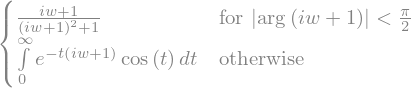

In [5]:
# ✏️ EDITA SOLO AQUÍ
FUNCION = "e^(-t)*cos(t)"
DESDE = 0
HASTA = "oo"

# 🛑 NO TOCAR DESDE AQUÍ
resolver_tf_integral(FUNCION, DESDE, HASTA)

## PANEL 4 — Transformada de Fourier por TRAMOS

### Transformada de Fourier por tramos

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

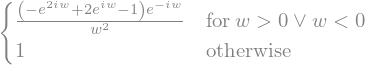

In [6]:
# ✏️ EDITA SOLO AQUÍ
TRAMOS = [
    ("1+t", -1, 0),
    ("1-t",  0, 1),
]

# 🛑 NO TOCAR DESDE AQUÍ
resolver_tf_tramos(TRAMOS)

## PANEL 5 — Transformada de Fourier INVERSA

Útil si te dan \(F(\omega)\) y piden regresar a \(f(t)\).

### Transformada inversa de Fourier

<IPython.core.display.Math object>

<IPython.core.display.Math object>

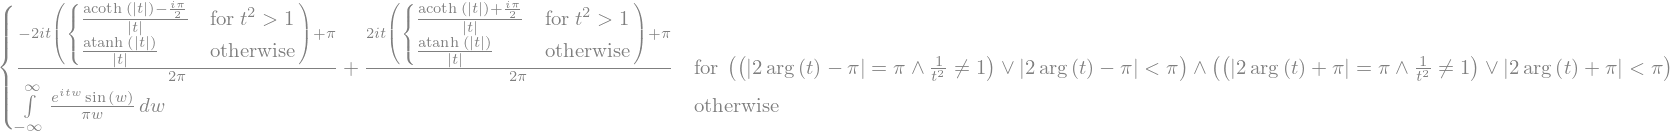

In [7]:
# ✏️ EDITA SOLO AQUÍ
F_OMEGA = "2*sin(w)/w"
DESDE_W = "-oo"
HASTA_W = "oo"

# 🛑 NO TOCAR DESDE AQUÍ
resolver_tfi_integral(F_OMEGA, DESDE_W, HASTA_W)

## PANEL 6 — PRIMER CORRIMIENTO: mover en frecuencia

Para problemas como:

- \(x(t)e^{j\omega_0t}\)
- \(x(t)\cos(\omega_0t)\)
- \(x(t)\sin(\omega_0t)\)

Este panel trabaja **a partir de una transformada conocida** \(X(\omega)\).

### Traslación en frecuencia

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

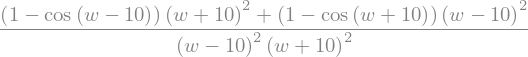

In [8]:
# ✏️ EDITA SOLO AQUÍ
F_BASE = "2*(1-cos(w))/w^2"
TIPO = "cos"          # "exp", "cos" o "sin"
W0 = 10
AMPLITUD = 1

# 🛑 NO TOCAR DESDE AQUÍ
resolver_corrimiento_frecuencia(F_BASE, tipo=TIPO, w0=W0, amplitud=AMPLITUD)

## PANEL 7 — SEGUNDO CORRIMIENTO: mover en el tiempo

Si tienes:

\[
x(t-t_0)
\]

pon directamente `T0 = t0`.

Ejemplo: \(x(t+5)=x(t-(-5))\), entonces `T0 = -5`.

### Traslación en el tiempo

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

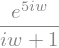

In [9]:
# ✏️ EDITA SOLO AQUÍ
F_BASE = "1/(1+I*w)"
T0 = -5

# 🛑 NO TOCAR DESDE AQUÍ
resolver_corrimiento_tiempo(F_BASE, T0)

## PANEL 8 — ⭐ Señal ampliada, movida, alargada y modulada

Este es el panel más importante para ejercicios del estilo:

> “Se conoce la TF de una señal y se busca la TF de otra que fue ampliada, movida o alargada.”

El panel usa:

\[
y(t)=K\,x\left(\frac{t-t_0}{a}\right)
\]

- `K`: amplía verticalmente.
- `ALARGAR = a`.
- `MOVER = t0`.
- Si `a > 1`, la señal queda **más ancha**.
- Modulación opcional: `"ninguna"`, `"exp"`, `"cos"`, `"sin"`.

### Transformación general de señal conocida

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

> Aquí `ALARGAR = a`: si a>1 la señal queda más ancha en el tiempo.

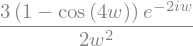

In [10]:
# ✏️ EDITA SOLO AQUÍ
F_BASE = "2*(1-cos(w))/w^2"
K = 3
ALARGAR = 4
MOVER = 2

MODULACION = "ninguna"   # "ninguna", "exp", "cos", "sin"
W_MOD = 0

# 🛑 NO TOCAR DESDE AQUÍ
resolver_transformacion_general(
    F_BASE,
    K=K,
    alargar=ALARGAR,
    mover=MOVER,
    modulacion=MODULACION,
    w_mod=W_MOD
)

## PANEL 9 — Si te dan directamente \(Kx(at+b)\)

Usa este cuando el examen escribe algo como:

\[
y(t)=2x(3t-6).
\]

No tienes que convertirlo manualmente a \(x((t-t_0)/a)\).

### Transformación directa \(Kx(at+b)\)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

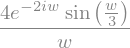

In [11]:
# ✏️ EDITA SOLO AQUÍ
F_BASE = "2*sin(w)/w"
K = 2
A_T = 3
B = -6

# 🛑 NO TOCAR DESDE AQUÍ
resolver_x_at_mas_b(F_BASE, K=K, A_t=A_T, B=B)

## PANEL 10 — Dualidad

Si conoces:

\[
f(t)\longleftrightarrow F(\omega)
\]

usa:

\[
F(t)\longleftrightarrow 2\pi f(-\omega).
\]

Ejemplo de la clave:

\[
u(t)e^{-3t}\longleftrightarrow\frac1{3+j\omega}.
\]

In [12]:
# ✏️ EDITA SOLO AQUÍ
F_DE_T = "Heaviside(t)*e^(-3*t)"
TRANSFORMADA = "1/(3+I*w)"

# 🛑 NO TOCAR DESDE AQUÍ
resolver_dualidad(F_DE_T, TRANSFORMADA)

### Principio de dualidad

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## PANEL 11 — Constante + senos/cosenos → DELTAS + espectro

Ejemplo de la clave:

\[
2-4\sin(\omega_0t).
\]

Cada componente se escribe:

- coseno: `(amplitud, frecuencia_angular)`
- seno: `(amplitud, frecuencia_angular)`

### Transformada con impulsos de Dirac

<IPython.core.display.Math object>


Picos del espectro:
ω = -1  | peso = -4*I*pi  | magnitud = 4*pi  | fase = -pi/2
ω = 0  | peso = 4*pi  | magnitud = 4*pi  | fase = 0
ω = 1  | peso = 4*I*pi  | magnitud = 4*pi  | fase = pi/2


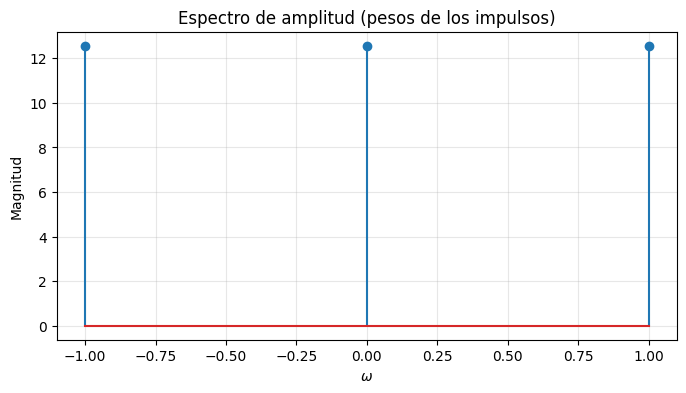

In [13]:
# ✏️ EDITA SOLO AQUÍ
DC = 2

COSENOS = [
    # (amplitud, w0)
]

SENOS = [
    (-4, 1),
]

GRAFICAR = True

# 🛑 NO TOCAR DESDE AQUÍ
resolver_deltas(DC, cosenos=COSENOS, senos=SENOS, graficar=GRAFICAR)

## PANEL 12 — Graficar espectro continuo de amplitud y fase

Pon aquí cualquier \(F(\omega)\) normal (no deltas).

### Espectro de amplitud y fase

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

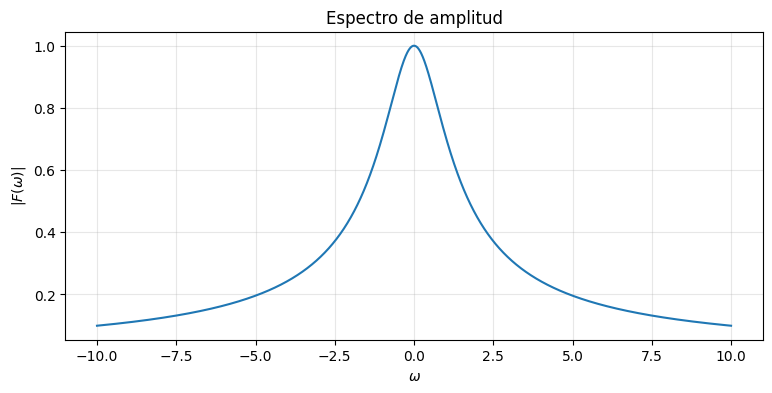

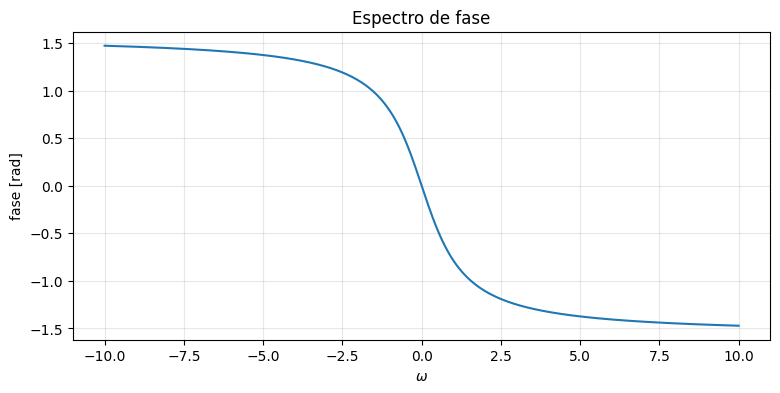

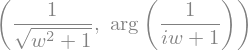

In [14]:
# ✏️ EDITA SOLO AQUÍ
F_OMEGA = "1/(1+I*w)"
W_MIN = -10
W_MAX = 10

# 🛑 NO TOCAR DESDE AQUÍ
resolver_espectro(F_OMEGA, W_MIN, W_MAX)

# 🟢 SECCIÓN EDO + FOURIER

La regla que usa esta sección es:

\[
P(D)y=f(t)
\]

si

\[
f(t)=\sum c_ne^{jn\omega_0t},
\]

entonces, cuando no hay resonancia:

\[
Y_n=\frac{c_n}{P(jn\omega_0)}.
\]

## PANEL 13 — EDO con entrada periódica POR TRAMOS

Escribe los coeficientes de la EDO como:

```text
[a0, a1, a2, ...]
```

Ejemplos:

- \(y'+y=f(t)\) → `[1,1]`
- \(y'+2y=f(t)\) → `[2,1]`
- \(y''-y=f(t)\) → `[-1,0,1]`
- \(y''+y=f(t)\) → `[1,0,1]`

El panel también revisa **resonancia**.

> ✅ Ahora este panel entrega la **solución general completa**, incluyendo resonancia cuando exista.

In [15]:
# ✏️ EDITA SOLO AQUÍ
COEFS_EDO = [1, 1]   # y' + y

TRAMOS = [
    (1, 0, pi),
    (0, pi, 2*pi),
]

PERIODO = 2*pi
REVISAR_HASTA_N = 9

# 🛑 NO TOCAR DESDE AQUÍ
_ = resolver_edo_fourier_tramos(
    COEFS_EDO,
    TRAMOS,
    PERIODO,
    N_resonancia=REVISAR_HASTA_N
)

### EDO con entrada periódica por tramos

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Solución homogénea:


✅ **No se detectó resonancia** en los armónicos revisados.

<IPython.core.display.Math object>

{'T': 2*pi,
 'w0': 1,
 'c0': 1/2,
 'cn': (-1)**(n + 1/2)/(2*pi*n) - I/(2*pi*n),
 'Y0': 1/2,
 'Yn': ((-1)**n - 1)/(2*pi*n*(n - I)),
 'den': I*n + 1,
 'resonancias': []}

## PANEL 14 — EDO cuando YA TE DAN la Serie Compleja

Ejemplo:

\[
f(t)=c_0+\sum c_ne^{jn\omega_0t}.
\]

Escribes directamente `C0`, `CN`, `W0`.

`PATRON` puede ser:

- `"todos"`
- `"impares"`
- `[1,3,5,7]`

> ✅ Ahora este panel entrega la **solución general completa**, no solo los coeficientes.

In [16]:
# ✏️ EDITA SOLO AQUÍ
COEFS_EDO = [2, 1]       # y' + 2y
C0 = "1/2"
CN = "1/(I*n*pi)"
W0 = 1
PATRON = "impares"
N = 9

# 🛑 NO TOCAR DESDE AQUÍ
_ = resolver_edo_cn(
    COEFS_EDO,
    C0,
    CN,
    W0,
    patron=PATRON,
    N=N
)

### EDO a partir de coeficientes complejos ya conocidos

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Chequeo de armónicos:
n=1: c_n=-I/pi, P=2 + I  -> ok
n=3: c_n=-I/(3*pi), P=2 + 3*I  -> ok
n=5: c_n=-I/(5*pi), P=2 + 5*I  -> ok
n=7: c_n=-I/(7*pi), P=2 + 7*I  -> ok
n=9: c_n=-I/(9*pi), P=2 + 9*I  -> ok

Homogénea:


{'Y0': 1/4, 'Yn': -I/(pi*n*(I*n + 2)), 'den': I*n + 2, 'resonancias': []}

## PANEL 15 — ⚠️ Resonancia / armónico individual

Úsalo cuando el Panel 13 o 14 diga **RESONANCIA**.

Resuelve:

\[
P(D)y=A\cos(\Omega t)+B\sin(\Omega t)
\]

y SymPy incluye automáticamente el factor \(t\) cuando corresponde.

Ejemplo de Tarea 2:

\[
y''+y=\frac{2}{\pi}\sin t.
\]

> ℹ️ Este panel queda como auxiliar para estudiar un armónico individual. Para la solución TOTAL usa 13 o 14.

### Armónico individual / resonancia

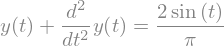

<IPython.core.display.Math object>

## ⚠️ Es un armónico resonante

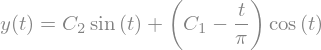

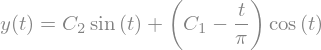

In [17]:
# ✏️ EDITA SOLO AQUÍ
COEFS_EDO = [1, 0, 1]   # y'' + y
A_COS = 0
B_SIN = "2/pi"
OMEGA = 1

# 🛑 NO TOCAR DESDE AQUÍ
_ = resolver_resonancia(COEFS_EDO, A_cos=A_COS, B_sin=B_SIN, Omega=OMEGA)

## PANEL 16 — Filtro RC pasa bajo

Para la aplicación opcional de la Tarea 2.

### Filtro RC pasa bajo

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Armónicos de una onda cuadrada impar:
n=1: |G|=sqrt(2)/2 ≈ 0.70711, fase=-pi/4 ≈ -0.78540 rad
      |Vi|=4/pi ; |Vo|=2*sqrt(2)/pi ≈ 0.90032
n=3: |G|=sqrt(10)/10 ≈ 0.31623, fase=-atan(3) ≈ -1.2490 rad
      |Vi|=4/(3*pi) ; |Vo|=2*sqrt(10)/(15*pi) ≈ 0.13421
n=5: |G|=sqrt(26)/26 ≈ 0.19612, fase=-atan(5) ≈ -1.3734 rad
      |Vi|=4/(5*pi) ; |Vo|=2*sqrt(26)/(65*pi) ≈ 0.049941
n=7: |G|=sqrt(2)/10 ≈ 0.14142, fase=-atan(7) ≈ -1.4289 rad
      |Vi|=4/(7*pi) ; |Vo|=2*sqrt(2)/(35*pi) ≈ 0.025723


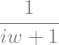

In [18]:
# ✏️ EDITA SOLO AQUÍ
RC = 1
ARMONICOS = (1, 3, 5, 7)
AMPLITUD_CUADRADA = 1

# 🛑 NO TOCAR DESDE AQUÍ
resolver_rc(RC=RC, armonicos=ARMONICOS, amplitud_cuadrada=AMPLITUD_CUADRADA)


## PANEL 17 — Modelo térmico de la Tarea 2

Para:

\[
y'+ay=
A_0+\sum_{n=1}^{\infty}
[A_n\cos(n\omega t)+B_n\sin(n\omega t)]
\]

con:

\[
y(0)=T_0.
\]

Este panel ahora calcula correctamente:

\[
y_{p,0}=\frac{A_0}{a}
\]

\[
C_n=\frac{aA_n-n\omega B_n}{a^2+n^2\omega^2}
\]

\[
D_n=\frac{n\omega A_n+aB_n}{a^2+n^2\omega^2}
\]

y también aplica automáticamente la condición inicial \(y(0)=T_0\).

Puedes dejar todo simbólico escribiendo `"a"`, `"A0"`, `"An"`, `"Bn"`, `"omega"` y `"T0"`.


### Modelo térmico

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

> Si te dan \(y(0)=T_0\), entonces \(C=T_0-y_p(0)\).

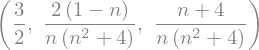

In [19]:
# ✏️ EDITA SOLO AQUÍ

A = "a"
A0 = "A0"
AN = "An"
BN = "Bn"
OMEGA = "omega"
T0 = "T0"

# 🛑 NO TOCAR DESDE AQUÍ
_ = resolver_termica(
    A,
    A0,
    AN,
    BN,
    OMEGA,
    T0=T0
)


## PANEL 18 — RLC con fuente en Serie Compleja

Para:

\[
q''+2\alpha q'+\omega^2q=\omega^2E
\]

\[
E=\sum\phi_ne^{jn\omega_0t}.
\]

### RLC en serie compleja

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

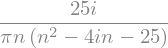

In [20]:
# ✏️ EDITA SOLO AQUÍ
ALPHA = 2
OMEGA_NATURAL = 5
OMEGA0 = 1
PHI_N = "1/(I*n*pi)"

# 🛑 NO TOCAR DESDE AQUÍ
resolver_rlc(ALPHA, OMEGA_NATURAL, OMEGA0, PHI_N)

## PANEL 19 — Viga / derivada de orden 4 con serie seno

Herramienta término a término para algo del tipo:

\[
C\,y^{(m)}
=
\sum F_n\sin(k_nx).
\]

Para el formato literal de la Tarea 2 puedes usar:

- `ORDEN = 4`
- `COEF_EDO = "E*I0"`
- `FN = "2*w0/(pi*L)*(-1)^(n+1)/n"`
- `KN = "n*pi"`

### EDO con serie seno término a término

<IPython.core.display.Math object>

<IPython.core.display.Math object>

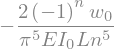

In [21]:
# ✏️ EDITA SOLO AQUÍ
ORDEN = 4
COEF_EDO = "E*I0"
FN = "2*w0/(pi*L)*(-1)^(n+1)/n"
KN = "n*pi"

# 🛑 NO TOCAR DESDE AQUÍ
resolver_serie_seno_derivada(ORDEN, COEF_EDO, FN, KN)

## PANEL 20 — Verificar una solución de EDO

Si sacaste una particular y quieres comprobarla:

\[
a_0y+a_1y'+a_2y''+\cdots = RHS.
\]

In [22]:
# ✏️ EDITA SOLO AQUÍ
COEFS_EDO = [1, 0, 1]
Y = "-t*cos(t)/pi"
RHS = "2*sin(t)/pi"

# 🛑 NO TOCAR DESDE AQUÍ
verificar_edo(COEFS_EDO, Y, RHS)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

✅ **La expresión satisface la EDO.**

# 🟣 PANEL F0 — FORMULARIO RÁPIDO

### Transformada
\[
F(\omega)=\int_{-\infty}^{\infty}f(t)e^{-j\omega t}dt
\]

### Inversa
\[
f(t)=\frac1{2\pi}\int_{-\infty}^{\infty}F(\omega)e^{j\omega t}d\omega
\]

### Tiempo
\[
x(t-t_0)\leftrightarrow X(\omega)e^{-j\omega t_0}
\]

### Frecuencia
\[
x(t)e^{j\omega_0t}\leftrightarrow X(\omega-\omega_0)
\]

### Escala temporal
\[
x(at)\leftrightarrow \frac1{|a|}X\left(\frac{\omega}{a}\right)
\]

### Alargamiento
\[
x(t/a)\leftrightarrow |a|X(a\omega)
\]

### Combinada
\[
Kx\left(\frac{t-t_0}{a}\right)
\leftrightarrow
K|a|e^{-j\omega t_0}X(a\omega)
\]

### Dualidad
\[
f(t)\leftrightarrow F(\omega)
\quad\Rightarrow\quad
F(t)\leftrightarrow2\pi f(-\omega)
\]

### Constante
\[
k\leftrightarrow2\pi k\delta(\omega)
\]

### Coseno
\[
\cos(\omega_0t)
\leftrightarrow
\pi[\delta(\omega-\omega_0)+\delta(\omega+\omega_0)]
\]

### Seno
\[
\sin(\omega_0t)
\leftrightarrow
\frac{\pi}{j}[\delta(\omega-\omega_0)-\delta(\omega+\omega_0)]
\]

### Exponencial unilateral
\[
u(t)e^{-at}\leftrightarrow\frac1{a+j\omega},
\qquad a>0
\]

### EDO + Fourier
\[
P(D)y=f(t),\qquad
Y_n=\frac{c_n}{P(jn\omega_0)}
\]

**Antes de dividir revisa si \(P(jn\omega_0)=0\): puede haber resonancia.**

# ✅ COBERTURA

Este notebook está pensado para cubrir:

- ✅ Serie compleja de Fourier.
- ✅ Serie compleja por tramos.
- ✅ Transformada de Fourier por integral.
- ✅ Transformada inversa.
- ✅ Primer corrimiento: frecuencia.
- ✅ Segundo corrimiento: tiempo.
- ✅ Ampliar, mover, comprimir y alargar señales.
- ✅ Transformación \(x(at+b)\).
- ✅ Dualidad.
- ✅ Constantes, senos, cosenos y deltas.
- ✅ Espectros de amplitud y fase.
- ✅ EDO con entradas periódicas.
- ✅ Detección de resonancia.
- ✅ Armónicos resonantes.
- ✅ Filtro RC.
- ✅ Modelo térmico de Tarea 2.
- ✅ RLC de Tarea 2.
- ✅ Viga/serie seno de Tarea 2.

## Ejercicios de la clave 2018

- Tema 1 → **Panel 1**
- Tema 2 → **Panel 3**
- Tema 3.1 → **Panel 6**
- Tema 3.2 → **Panel 7**
- Tema 4.1 → **Panel 10**
- Tema 4.2 → **Panel 11**

## Temario actual que te pasaron

- Solución de ecuaciones diferenciales → **Paneles 13–20**
- Serie compleja de Fourier → **Paneles 1–2**
- Transformaciones de señales → **Paneles 6–12**

# ✅ REGLA FINAL

- Ejecuta **CARGAR HERRAMIENTA** una sola vez.
- No edites la celda interna.
- Cambia únicamente lo marcado como **✏️ EDITA SOLO AQUÍ**.
- Ejecuta ese mismo panel.
- Si reinicias el kernel, vuelve a ejecutar **CARGAR HERRAMIENTA**.
- Si un resultado dice **RESONANCIA**, no dividas entre cero: usa el **Panel 15**.